In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

In [14]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
c = 3e8 # m/s
lambda_ = 1.55*um
f_ = c/lambda_

## Parametros do guia de onda

neff = 2.445
ng = 4.248

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

# Anel All-Pass #

Um anel all-pass é um dispositivo fotônico com a seguinte estrutura:

<p align="center">
  <img src="Imagens/Anel all-pass.png" width="550" />
</p>

Esse dispositivo pode ser visto como um acoplador direcional realimentado.

<p align="center">
  <img src="Imagens/Modelo analitico do anel all-pass.png" width="550" />
</p>

Onde $r$ é o fator de auto-acoplamento do acoplador direcional e $a$ e $\phi$ são, respectivamente, a atenuação do modo e a sua defasagem em uma volta completa no guia curvo. Com isso, determina-se a função de transferência desse dispositivo:

$$\frac{E_{pass}}{E_{in}} = t = \frac{r-ae^{-j\phi}}{1-rae^{-j\phi}}\,.$$

Sua transmitância é:

$$T_n = |t|^2 = \frac{r^2 - 2ra\cos{(\phi)}+a^2}{1-2ra\cos{(\phi)}+(ra)^2}\,.$$

In [15]:
def phi(lambda_, L, n_eff=neff):
    num = 2*pi*n_eff*L
    den = lambda_
    return num/den

def t(phi, r, a):
    num = r - a*np.exp(-1j*phi)
    den = 1 - r*a*np.exp(-1j*phi)
    return num/den

def Tn(phi, r, a):
    num = r**2 - 2*r*a*np.cos(phi) + a**2
    den = 1 - 2*r*a*np.cos(phi) + (r*a)**2
    return num/den

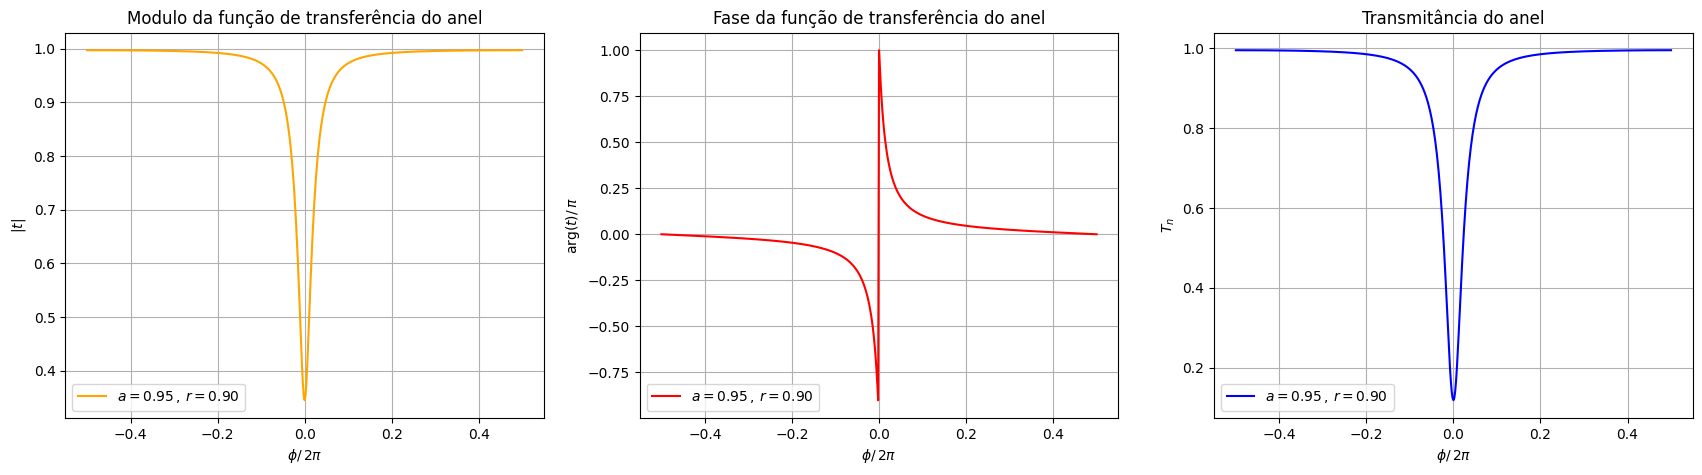

In [16]:
r = 0.9
a = 0.95

phi_array = np.linspace(-pi,pi,501)

t_array = t(phi_array, r, a)
Tn_array = Tn(phi_array, r, a)

fig, ax = plt.subplots(1,3, figsize = (21,5))

ax[0].plot(phi_array/(2*pi), np.abs(t_array), color = 'orange', label = r'$a=%.2f\,,\,r=%.2f$' %(a,r))
ax[0].set_title('Modulo da função de transferência do anel')
ax[0].set_xlabel(r'$\phi/\,2\pi$')
ax[0].set_ylabel(r'$|t|$')
ax[0].grid(True)
ax[0].legend(loc = 'lower left')

ax[1].plot(phi_array/(2*pi), np.angle(t_array)/(pi), color = 'red', label = r'$a=%.2f\,,\,r=%.2f$' %(a,r))
ax[1].set_title('Fase da função de transferência do anel')
ax[1].set_xlabel(r'$\phi/\,2\pi$')
ax[1].set_ylabel(r'$\arg(t)/\,\pi$')
ax[1].grid(True)
ax[1].legend(loc = 'lower left')

ax[2].plot(phi_array/(2*pi), Tn_array, color = 'blue', label = r'$a=%.2f\,,\,r=%.2f$' %(a,r))
ax[2].set_title('Transmitância do anel')
ax[2].set_xlabel(r'$\phi/\,2\pi$')
ax[2].set_ylabel(r'$T_n$')
ax[2].grid(True)
ax[2].legend(loc = 'lower left')

plt.show()

## Frequência de ressonância ##

A ressonância do anel ocorre quando $\phi = 2m\pi$, isto é, quando:

$$\lambda = \frac{n_{eff}L}{m}\,,\,m=1,2,3,...\,.$$

As frequências onde a ressonância ocorre são denominadas frequências de ressonância do anel, $\lambda_{res}$.

In [17]:
def lambda_res(L, n_eff=neff, m=1):
    num = n_eff*L
    den = m
    return num/den

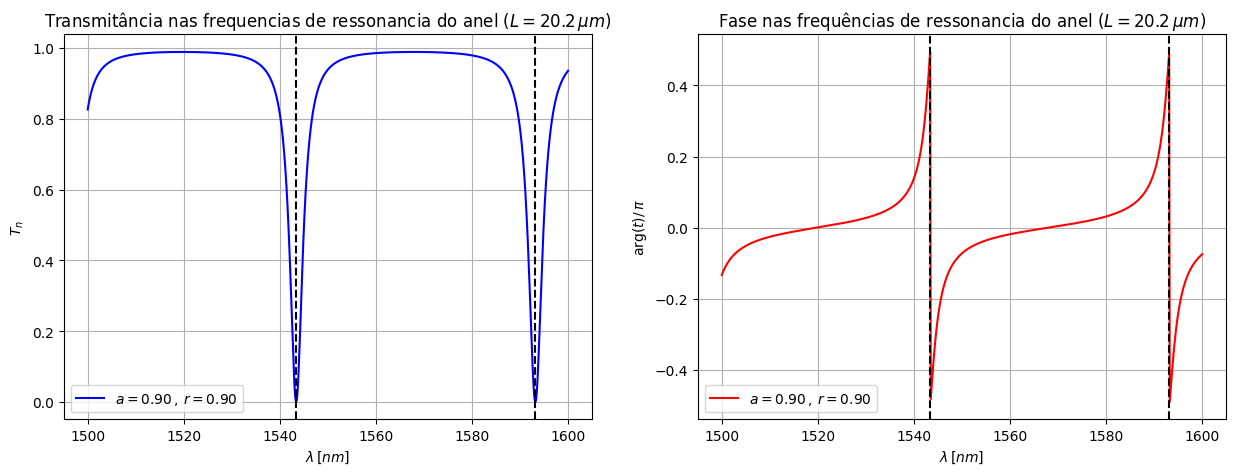

In [18]:
r = 0.9
a = 0.9
L = 20.2*um

lambda_array = np.linspace(1500, 1600, 801)*nm
phi_array = phi(lambda_array, L)

t_array = t(phi_array, r, a)
Tn_array = Tn(phi_array, r, a)

fig, ax = plt.subplots(1,2, figsize = (15,5))

ax[0].plot(lambda_array/nm, Tn_array, color = 'blue', label = r'$a=%.2f\,,\,r=%.2f$' %(a,r))
for m in range(1,50,1):
    lambda_ress = lambda_res(L, m=m)
    if (lambda_ress >= lambda_array[0]) and (lambda_ress <= lambda_array[-1]):
        ax[0].axvline(lambda_ress/nm, color = 'black', linestyle = '--')
ax[0].set_title(r'Transmitância nas frequencias de ressonancia do anel ($L=%.1f\,\mu m$)' %(L/um))
ax[0].set_xlabel(r'$\lambda\,[nm]$')
ax[0].set_ylabel(r'$T_n$')
#ax[0].set_xlim([1530,1565])
ax[0].grid(True)
ax[0].legend(loc = 'lower left')

ax[1].plot(lambda_array/nm, np.angle(t_array)/(pi), color = 'red', label = r'$a=%.2f\,,\,r=%.2f$' %(a,r))
for m in range(1,50,1):
    lambda_ress = lambda_res(L, m=m)
    if (lambda_ress >= lambda_array[0]) and (lambda_ress <= lambda_array[-1]):
        ax[1].axvline(lambda_ress/nm, color = 'black', linestyle = '--')
ax[1].set_title(r'Fase nas frequências de ressonancia do anel ($L=%.1f\,\mu m$)' %(L/um))
ax[1].set_xlabel(r'$\lambda\,[nm]$')
ax[1].set_ylabel(r'$\arg(t)/\,\pi$')
#ax[1].set_xlim([1530,1565])
ax[1].grid(True)
ax[1].legend(loc = 'lower left')

plt.show()

## Ressonância por voltas ##

Utilizando a expansão em série de potências:

$$\frac{1}{1-z}=\sum\limits_{n=0}^{\infty}z^{n}\,,\,|z|<1\,.$$

Chegamos a:

$$t=r-\kappa^2ae^{-j\phi}\sum\limits_{n=0}^{\infty}\left(rae^{-j\phi}\right)^n\,.$$

Que pode ser vista da forma:

$$t=\lim_{n\to\infty}t_N\,,$$
$$t_N =r-\kappa^2ae^{-j\phi}\sum\limits_{n=0}^{N-1}\left(rae^{-j\phi}\right)^n\,.$$

Onde $N$ é o número de voltas no anel.

In [19]:
def t_N(phi, N, r, a):
    kappa2 = 1 - r**2
    A = kappa2*a*np.exp(-1j*phi)
    sum = 0
    for n in range(0,N,1):
        a_n = np.power(r*a*np.exp(-1j*phi), n)
        sum += a_n
    return r - A*sum

[]

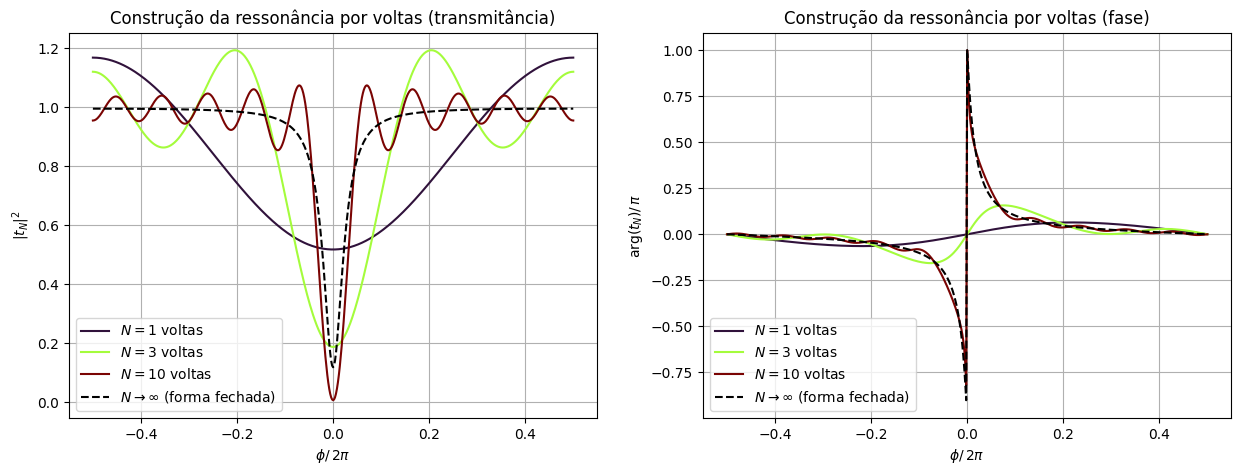

In [20]:
r = 0.9
a = 0.95

phi_array = np.linspace(-pi,pi,501)
N_array = [1,3,10]

tN_matrix = []
for N in N_array:
    tN = t_N(phi_array, N, r, a)
    tN_matrix.append(tN)

fig, ax = plt.subplots(1,2, figsize = (15,5))

for k in range(0,len(N_array),1):
    ax[0].plot(phi_array/(2*pi), np.abs(tN_matrix[k])**2, color=cmap6(k/(len(N_array)-1)), label = r'$N=%d$ voltas' %(N_array[k]))
ax[0].plot(phi_array/(2*pi), Tn(phi_array, r, a), color = 'black', label = r'$N\to\infty$ (forma fechada)', linestyle = '--')
ax[0].set_title('Construção da ressonância por voltas (transmitância)')
ax[0].set_xlabel(r'$$')
ax[0].set_xlabel(r'$\phi/\,2\pi$')
ax[0].set_ylabel(r'$|t_N|^2$')
ax[0].grid(True)
ax[0].legend(loc = 'lower left')

for k in range(0,len(N_array),1):
    ax[1].plot(phi_array/(2*pi), np.angle(tN_matrix[k])/(pi), color=cmap6(k/(len(N_array)-1)), label = r'$N=%d$ voltas' %(N_array[k]))
ax[1].plot(phi_array/(2*pi), np.angle(t(phi_array, r, a))/(pi), color = 'black', label = r'$N\to\infty$ (forma fechada)', linestyle = '--')
ax[1].set_title('Construção da ressonância por voltas (fase)')
ax[1].set_xlabel(r'$$')
ax[1].set_xlabel(r'$\phi/\,2\pi$')
ax[1].set_ylabel(r'$\arg(t_N)/\,\pi$')
ax[1].grid(True)
ax[1].legend(loc = 'lower left')

plt.plot()

## Regimes de acoplamento ##

Os aneis possuem 3 regimes de acoplamento possíveis:

1) Subacoplado, quando $r>a$;

2) Crítico, quando $r=a$;

3) Sobreacoplado, quando $r<a$.

### Regime subacoplado ###

No regime subacoplado, $r>a$, logo:

$$r^2 > a^2$$
$$1-\kappa^2 > a^2$$
$$1-a^2 > \kappa^2$$

As perdas no guia curvo são dominantes em relação ao que é transmitido a ele. Fazendo com que seja necessário mais potência óptica no anel. Nesse regime, a fase oscila em torno de 0.

### Regime crítico ###

No regime crítico, $r=a$, logo:

$$1-a^2 = \kappa^2$$

As perdas no guia curvo e o que é transmitido para ele estão na mesma proporção. Nesse regime, a fase salta em $\pi$ durante a ressonância e, nela, $T_n = 0$, ou seja, não a potência de saída no anel.

### Regime sobreacoplado ###

No regime sobreacoplado, $r<a$, logo

$$1-a^2 < \kappa^2$$

As perdas no guia curvo são menores do que é transmitido para ele. Nesse regime, a fase é acumulada na saída, podendo dar voltas completas.

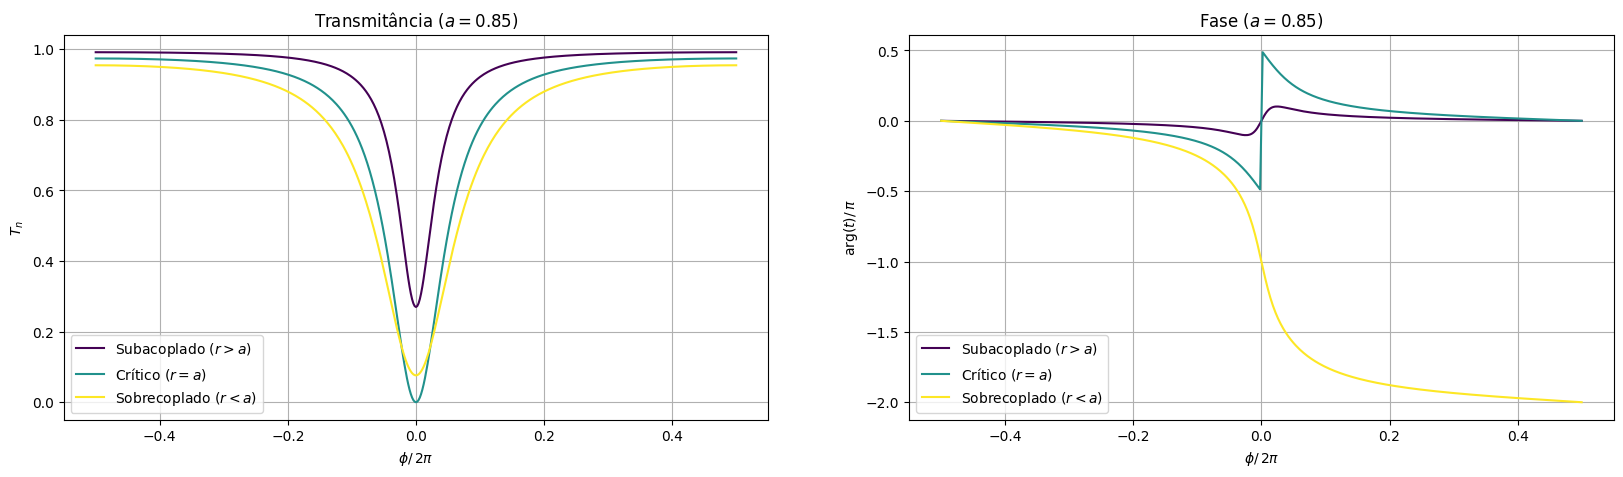

In [21]:
a = 0.85
r_array = [0.95, 0.85, 0.75]

phi_array = np.linspace(-pi, pi, 501)

fig, ax = plt.subplots(1,2, figsize = (20,5))

for k in range(0, len(r_array), 1):
    r = r_array[k]
    if r > a:
        label = r'Subacoplado ($r>a$)'
    elif r == a:
        label = r'Crítico ($r=a$)'
    else:
        label = r'Sobrecoplado ($r<a$)'

    ax[0].plot(phi_array/(2*pi), Tn(phi_array, r, a), color=cmap1(k/(len(N_array)-1)), label = label)    
    fase_array = np.angle(t(phi_array, r, a))/(pi)
    if r < a:
        fase_array = np.where(fase_array < 0, fase_array, fase_array - 2)
    ax[1].plot(phi_array/(2*pi), fase_array, color=cmap1(k/(len(N_array)-1)), label = label)

ax[0].set_title(r'Transmitância ($a = %.2f$)' %a)
ax[0].grid(True)
ax[0].set_xlabel(r'$\phi/\,2\pi$')
ax[0].set_ylabel(r'$T_n$')
ax[0].legend(loc = 'lower left')

ax[1].set_title(r'Fase ($a = %.2f$)' %a)
ax[1].grid(True)
ax[1].set_xlabel(r'$\phi/\,2\pi$')
ax[1].set_ylabel(r'$\arg(t)/\,\pi$')
ax[1].legend(loc = 'lower left')

plt.show() 


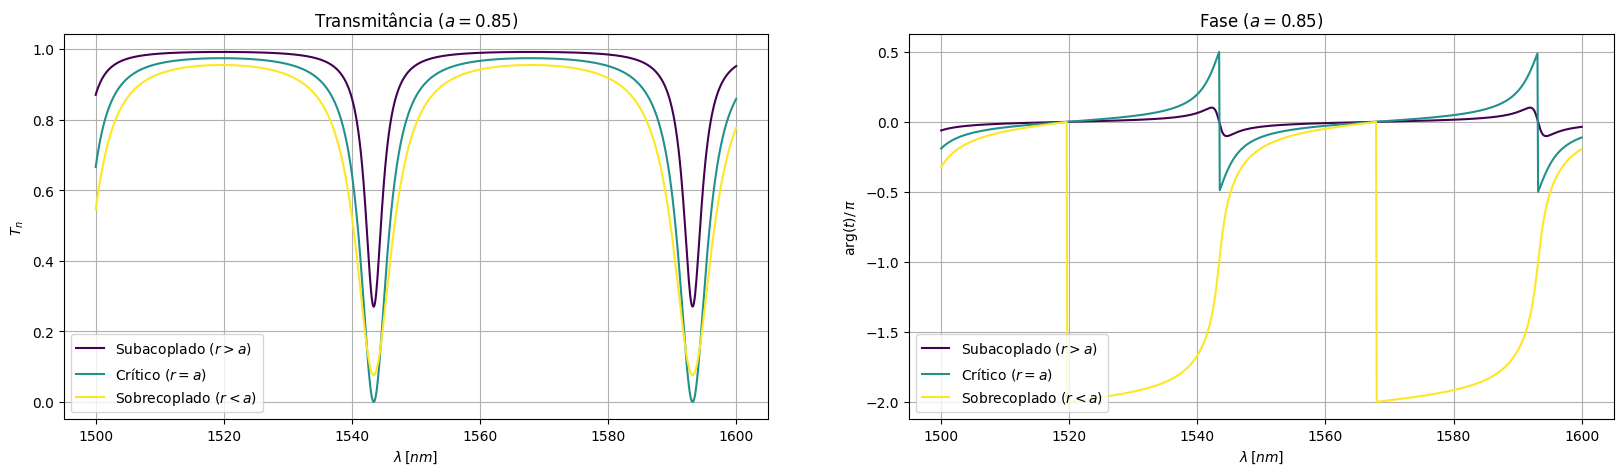

In [22]:
a = 0.85
r_array = [0.95, 0.85, 0.75]
L = 20.2*um

lambda_array = np.linspace(1500, 1600, 1001)*nm
phi_array = phi(lambda_array, L)

fig, ax = plt.subplots(1,2, figsize = (20,5))

for k in range(0, len(r_array), 1):
    r = r_array[k]
    if r > a:
        label = r'Subacoplado ($r>a$)'
    elif r == a:
        label = r'Crítico ($r=a$)'
    else:
        label = r'Sobrecoplado ($r<a$)'

    ax[0].plot(lambda_array/nm, Tn(phi_array, r, a), color=cmap1(k/(len(r_array)-1)), label = label)    
    fase_array = np.angle(t(phi_array, r, a))/(pi)
    if r < a:
        fase_array = np.where(fase_array < 0, fase_array, fase_array - 2)
    ax[1].plot(lambda_array/nm, fase_array, color=cmap1(k/(len(r_array)-1)), label = label)

ax[0].set_title(r'Transmitância ($a = %.2f$)' %a)
ax[0].grid(True)
ax[0].set_xlabel(r'$\lambda\,[nm]$')
ax[0].set_ylabel(r'$T_n$')
ax[0].legend(loc = 'lower left')

ax[1].set_title(r'Fase ($a = %.2f$)' %a)
ax[1].grid(True)
ax[1].set_xlabel(r'$\lambda\,[nm]$')
ax[1].set_ylabel(r'$\arg(t)/\,\pi$')
ax[1].legend(loc = 'lower left')

plt.show() 

## Atraso de grupo ##

O atraso de grupo de um anel all-pass, $\tau_g$, é dado por:

$$\tau_g = \frac{\lambda^2}{2\pi c}\cdot\frac{d\Phi}{d\lambda} = -T_{volta}\frac{d\Phi}{d\phi}\,,$$

$$\Phi = \tan^{-1}{\left[\frac{a\sin{(\phi)}}{r-a\cos{(\phi)}}\right]} - \tan^{-1}{\left[\frac{ra\sin{(\phi)}}{1-ra\cos{(\phi)}}\right]}\,,$$

$$T_{volta} = \frac{n_g L}{c}\,.$$

Onde $T_{volta}$ é o tempo que leva para dar uma volta no anel e $\Phi$ é a fase da função de transferência do anel, $t$. Na ressonância ($\phi = 0$):

$$\frac{t_g}{T_{volta}} = \frac{a\left(1-r^2\right)}{(a-r)(1-ra)}\,$$

para um anel sem perdas ($a=1$ e $T_n = 0$):

$$\frac{t_g}{T_n} = \frac{1+r}{1-r}\,.$$

In [23]:
def Phi(phi, r, a):
    arg1 = a*np.sin(phi) / (r-a*np.cos(phi))
    arg2 = r*a*np.sin(phi) / (1 - r*a*np.cos(phi))
    return np.arctan(arg1) - np.arctan(arg2)

def T_volta(L, n_g = ng):
    num = n_g*L
    den = c
    return num/den

def tg_ressonancia(r,a,L,n_g = ng):
    Tvolta = T_volta(L, n_g)
    num = Tvolta*a*(1-r**2)
    den = (a-r)*(1-r*a)
    return num/den

[]

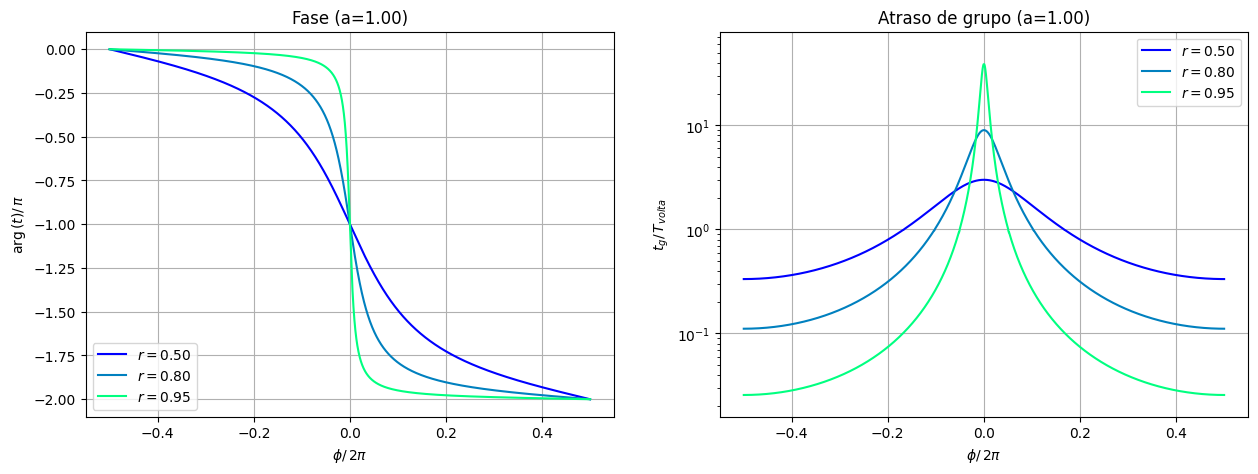

In [24]:
a = 1
r_array = [0.50, 0.80, 0.95]
L = 20.2*um

Tvolta = T_volta(L)

phi_array = np.linspace(-pi, pi, 2001)
fase_matrix = []
tg_matrix = []

dphi = phi_array[1] - phi_array[0]

for r in r_array:
    # Calculo da fase da função de transferência
    fase_array = np.angle(t(phi_array, r, a))
    fase_array = np.where(fase_array < 0, fase_array, fase_array - 2*pi)

    # Calculo do atraso de grupo
    Phi_array = Phi(phi_array, r, a)
    DPhi_array = np.zeros(len(Phi_array))   

    for k in range(0, len(Phi_array), 1):
        if k == 0:
            km1 = -1
        else:
            km1 = k-1
        DPhi_array[k] = (Phi_array[k] - Phi_array[km1])/dphi

    DPhi_array = medfilt(DPhi_array, kernel_size=5)
    tg_array = -Tvolta * DPhi_array

    # Finalizando
    fase_matrix.append(fase_array)
    tg_matrix.append(tg_array)

fig, ax = plt.subplots(1,2, figsize = (15,5))

for k in range(0,len(r_array),1):
    ax[0].plot(phi_array/(2*pi), fase_matrix[k]/pi, color=cmap8(k/(len(r_array)-1)), label = r'$r=%.2f$' %r_array[k])
    ax[1].semilogy(phi_array[1:]/(2*pi), tg_matrix[k][1:]/Tvolta, color=cmap8(k/(len(r_array)-1)), label = r'$r=%.2f$' %r_array[k])

ax[0].grid(True)
ax[0].set_xlabel(r'$\phi/\,2\pi$')
ax[0].set_ylabel(r'$\arg{(t)}/\,\pi$')
ax[0].legend(loc = 'lower left')
ax[0].set_title(r'Fase (a=%.2f)' %a)

ax[1].grid(True)
ax[1].set_xlabel(r'$\phi/\,2\pi$')
ax[1].set_ylabel(r'$t_g/\,T_{volta}$')
ax[1].legend(loc = 'upper right')
ax[1].set_title(r'Atraso de grupo (a=%.2f)' %a)
ax[1].set_ylim([10**(-1.8), 10**(1.9)])

plt.plot()